# 05 費用対効果の感度分析

## 1. 分析の目的

確定済みのRandom ForestモデルがFinal Testで高リスクと判定した予約を対象に、キャンセル対策の費用対効果を試算します。施策コスト、キャンセル防止1件あたりの追加利益、キャンセル削減率を変え、どの条件で黒字・赤字になるかを確認します。

このNotebookはモデルの再学習や再選択を行いません。対象件数12,022件と対象内の実キャンセル6,670件は過去のFinal Testから得た集計値です。金額と削減率は実績ではなく仮定であり、将来の施策効果を保証しません。

In [1]:
# 共通の費用対効果計算関数を読み込む
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.roi_simulator import (
    ACTUAL_CANCELLATIONS,
    DEFAULT_INTERVENTION_COST,
    DEFAULT_PROFIT_PER_PREVENTED,
    DEFAULT_REDUCTION_RATE,
    TARGET_BOOKINGS,
    build_sensitivity_table,
    calculate_roi,
)

sns.set_theme(style="whitegrid")
COLORS = {"profit": "#13795b", "loss": "#c0392b", "main": "#247BA0"}

## 2. 基準ケースの再現

04_Business_Recommendations.ipynbとREADMEで使用した条件を、共通関数で再計算します。

- 施策対象件数：12,022件（過去Final Testの予測結果）
- 対象内の実キャンセル件数：6,670件（過去Final Testの正解ラベルによる事後集計）
- 施策コスト：300円/予約（仮定）
- 防止1件あたり追加利益：12,000円（仮定）
- キャンセル削減率：5%（仮定）

In [2]:
# 既存の基準ケースを再計算する
baseline = calculate_roi()
baseline_table = pd.DataFrame({
    "項目": [
        "施策対象件数", "対象内の実キャンセル件数", "想定防止件数",
        "施策費用", "追加利益", "差引利益", "損益分岐削減率", "ROI"
    ],
    "値": [
        f"{baseline.target_bookings:,}件",
        f"{baseline.actual_cancellations:,}件",
        f"{baseline.prevented_cancellations:,.1f}件",
        f"{baseline.total_cost:,.0f}円",
        f"{baseline.incremental_profit:,.0f}円",
        f"{baseline.net_profit:,.0f}円",
        f"{baseline.break_even_rate:.2%}",
        f"{baseline.roi:.2%}",
    ],
})
display(baseline_table)

# README記載の395,400円を再現できていることを確認する
assert baseline.net_profit == 395_400

,項目,値
0,施策対象件数,"12,022件"
1,対象内の実キャンセル件数,"6,670件"
2,想定防止件数,333.5件
3,施策費用,"3,606,600円"
4,追加利益,"4,002,000円"
5,差引利益,"395,400円"
6,損益分岐削減率,4.51%
7,ROI,10.96%


基準ケースでは、施策費用3,606,600円に対し、想定追加利益は4,002,000円、差引利益は395,400円です。損益分岐となる削減率は約4.51%であるため、仮定した5%は損益分岐点をわずかに上回ります。小さな前提の変化で赤字になる可能性があり、感度分析が必要です。

## 3. 施策コスト・追加利益・削減率ごとの比較

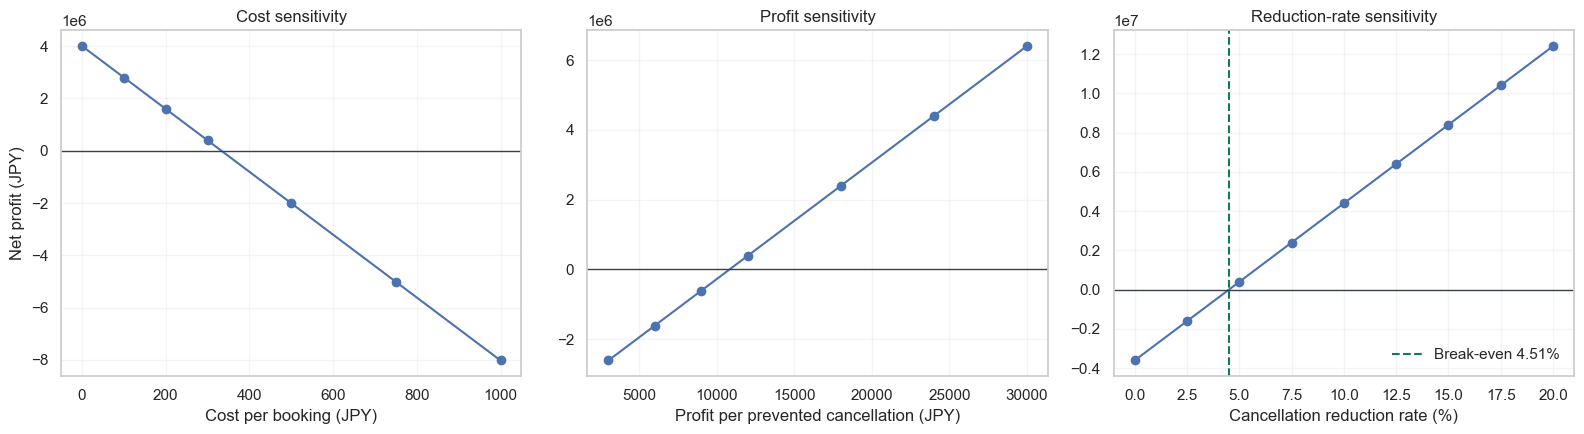

In [3]:
# 1つの前提だけを変え、差引利益への影響を比較する
cost_values = np.array([0, 100, 200, 300, 500, 750, 1000])
profit_values = np.array([3000, 6000, 9000, 12000, 18000, 24000, 30000])
reduction_values = np.arange(0, 0.201, 0.025)

cost_sensitivity = build_sensitivity_table(
    intervention_costs=cost_values,
    profits_per_prevented=[DEFAULT_PROFIT_PER_PREVENTED],
    reduction_rates=[DEFAULT_REDUCTION_RATE],
)
profit_sensitivity = build_sensitivity_table(
    intervention_costs=[DEFAULT_INTERVENTION_COST],
    profits_per_prevented=profit_values,
    reduction_rates=[DEFAULT_REDUCTION_RATE],
)
reduction_sensitivity = build_sensitivity_table(
    intervention_costs=[DEFAULT_INTERVENTION_COST],
    profits_per_prevented=[DEFAULT_PROFIT_PER_PREVENTED],
    reduction_rates=reduction_values,
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(cost_sensitivity["intervention_cost"], cost_sensitivity["net_profit"], marker="o")
axes[0].axhline(0, color="#374151", linewidth=1)
axes[0].set(title="Cost sensitivity", xlabel="Cost per booking (JPY)", ylabel="Net profit (JPY)")

axes[1].plot(profit_sensitivity["profit_per_prevented"], profit_sensitivity["net_profit"], marker="o")
axes[1].axhline(0, color="#374151", linewidth=1)
axes[1].set(title="Profit sensitivity", xlabel="Profit per prevented cancellation (JPY)")

axes[2].plot(reduction_sensitivity["reduction_rate"] * 100, reduction_sensitivity["net_profit"], marker="o")
axes[2].axhline(0, color="#374151", linewidth=1)
axes[2].axvline(baseline.break_even_rate * 100, color=COLORS["profit"], linestyle="--", label=f"Break-even {baseline.break_even_rate:.2%}")
axes[2].set(title="Reduction-rate sensitivity", xlabel="Cancellation reduction rate (%)")
axes[2].legend(frameon=False)

for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [4]:
# 比較表として数値も確認する
comparison_table = reduction_sensitivity[[
    "reduction_rate", "prevented_cancellations", "total_cost",
    "incremental_profit", "net_profit", "roi", "is_profitable"
]].copy()
comparison_table.columns = ["削減率", "防止件数", "施策費用", "追加利益", "差引利益", "ROI", "黒字か"]
display(comparison_table.style.format({
    "削減率": "{:.1%}", "防止件数": "{:,.1f}", "施策費用": "{:,.0f}円",
    "追加利益": "{:,.0f}円", "差引利益": "{:,.0f}円", "ROI": "{:.1%}"
}))

,削減率,防止件数,施策費用,追加利益,差引利益,ROI,黒字か
0,0.0%,0.0,"3,606,600円",0円,"-3,606,600円",-100.0%,False
1,2.5%,166.8,"3,606,600円","2,001,000円","-1,605,600円",-44.5%,False
2,5.0%,333.5,"3,606,600円","4,002,000円","395,400円",11.0%,True
3,7.5%,500.3,"3,606,600円","6,003,000円","2,396,400円",66.4%,True
4,10.0%,667.0,"3,606,600円","8,004,000円","4,397,400円",121.9%,True
5,12.5%,833.8,"3,606,600円","10,005,000円","6,398,400円",177.4%,True
6,15.0%,"1,000.5","3,606,600円","12,006,000円","8,399,400円",232.9%,True
7,17.5%,"1,167.2","3,606,600円","14,007,000円","10,400,400円",288.4%,True
8,20.0%,"1,334.0","3,606,600円","16,008,000円","12,401,400円",343.9%,True


## 4. 複数条件のヒートマップ

削減率を5%に固定し、施策コストと防止1件あたり追加利益の組み合わせを比較します。緑は黒字、赤は赤字です。黒字・赤字の境界は前提値に依存するため、実際の運用コストと利益構造へ置き換えて判断します。

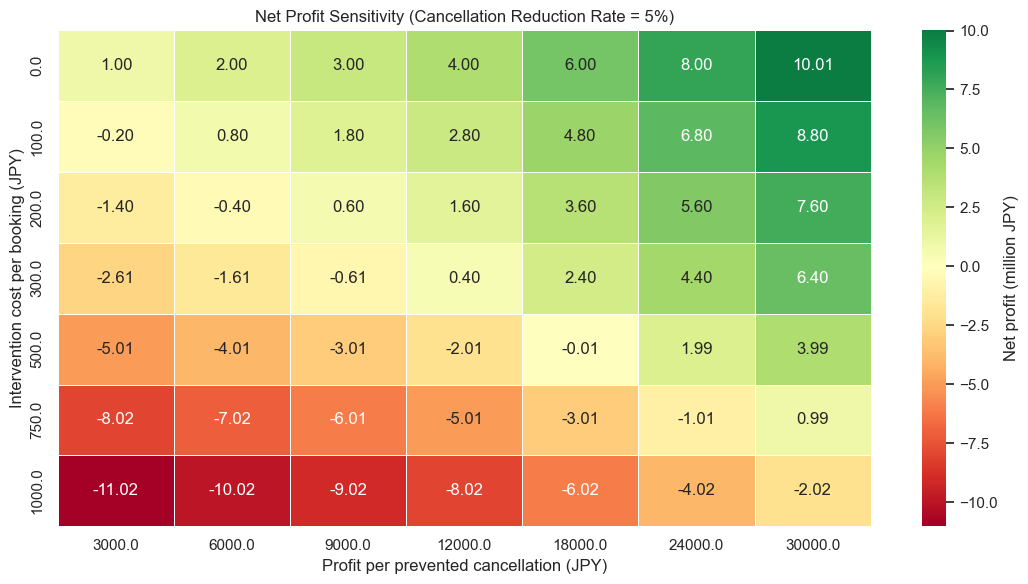

Saved: images\roi_sensitivity_heatmap.png


In [5]:
# 費用と追加利益の全組み合わせを計算する
heatmap_data = build_sensitivity_table(
    intervention_costs=cost_values,
    profits_per_prevented=profit_values,
    reduction_rates=[DEFAULT_REDUCTION_RATE],
)
heatmap_pivot = heatmap_data.pivot(
    index="intervention_cost", columns="profit_per_prevented", values="net_profit"
)

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(
    heatmap_pivot / 1_000_000,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Net profit (million JPY)"},
    ax=ax,
)
ax.set(
    title="Net Profit Sensitivity (Cancellation Reduction Rate = 5%)",
    xlabel="Profit per prevented cancellation (JPY)",
    ylabel="Intervention cost per booking (JPY)",
)
plt.tight_layout()

# README掲載用に同じグラフを保存する
image_path = PROJECT_ROOT / "images" / "roi_sensitivity_heatmap.png"
image_path.parent.mkdir(exist_ok=True)
fig.savefig(image_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {image_path.relative_to(PROJECT_ROOT)}")

In [6]:
# 黒字・赤字となる条件数を確認する
profitability_summary = (
    heatmap_data.groupby("is_profitable")
    .size()
    .rename(index={True: "黒字", False: "赤字"})
    .rename("条件数")
    .to_frame()
)
display(profitability_summary)

break_even_table = pd.DataFrame({
    "施策コスト（円/予約）": cost_values,
    "損益分岐削減率": [
        calculate_roi(intervention_cost=cost).break_even_rate for cost in cost_values
    ],
})
display(break_even_table.style.format({"損益分岐削減率": "{:.2%}"}))

,条件数
is_profitable,
赤字,24
黒字,25


,施策コスト（円/予約）,損益分岐削減率
0,0,0.00%
1,100,1.50%
2,200,3.00%
3,300,4.51%
4,500,7.51%
5,750,11.26%
6,1000,15.02%


## 5. 結果の読み方と今後の確認事項

### 分析から分かること

- 基準ケースの差引利益395,400円を再現できました。
- 損益分岐削減率は約4.51%で、削減率5%の基準ケースには大きな余裕がありません。
- 施策コストが高くなるほど、防止1件あたりの利益または削減率を高くする必要があります。
- Streamlitアプリでは同じ共通関数を使い、入力値を変更してこの関係を対話的に確認できます。

### 注意点

6,670件は過去のFinal Testにおいて高リスク群で実際にキャンセルされた件数であり、将来も同じ割合になるとは限りません。300円と12,000円は実証的な根拠がある値ではなく、5%の削減率も仮定です。これは施策を実施した実績ではありません。

実運用では、連絡チャネル別の人件費・配信費、予約単位の宿泊日数、限界利益、キャンセル料、空室の再販売率を調査して前提を更新します。その後、確定済みモデルで対象を抽出し、Treatment群とControl群へ無作為割付するA/Bテストでキャンセル削減率と利益改善を検証します。SHAPの寄与も因果効果とは解釈しません。